<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

-Juan Manuel Vellaizan
-Maria Paula Orozco

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [1]:
### TU CÓDIGO AQUÍ ###
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Configuraciones de visualización
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [3]:
### TU CÓDIGO AQUÍ ###
import os
import pandas as pd

ruta_archivo = None

for ruta, carpetas, archivos in os.walk("/"):
    if "Indicators.csv" in archivos:
        ruta_archivo = os.path.join(ruta, "Indicators.csv")
        break

if ruta_archivo is None:
    raise FileNotFoundError(
        "No se encontró Indicators.csv. "
        "Verifica que esté disponible en el entorno."
    )

df_indicators = pd.read_csv(ruta_archivo)

In [4]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [5]:
print("\nInformación general del DataFrame:")
df_indicators.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [6]:
### TU CÓDIGO AQUÍ ###
import os
import pandas as pd

ruta_archivo = None

for ruta, carpetas, archivos in os.walk("/"):
    if "Country.csv" in archivos:
        ruta_archivo = os.path.join(ruta, "Country.csv")
        break

if ruta_archivo is None:
    raise FileNotFoundError("No se encontró Country.csv. Verifica que esté disponible en el entorno.")

df_countries = pd.read_csv(ruta_archivo)

In [7]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(14, 3)


In [9]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CountryCode  14 non-null     object
 1   ShortName    14 non-null     object
 2   Region       14 non-null     object
dtypes: object(3)
memory usage: 468.0+ bytes


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [11]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [13]:
### TU CÓDIGO AQUÍ ###
df_indicators['IndicatorCode'] = df_indicators['IndicatorCode'].replace(nombre_indicadores)

2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [14]:
### TU CÓDIGO AQUÍ ###
df_pivot = df_indicators.pivot_table(
    index='CountryCode',
    columns='IndicatorCode',
    values='Value'
).reset_index()

df_pivot.columns.name = None

2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [15]:
### TU CÓDIGO AQUÍ ###
df_final = pd.merge(
    df_pivot,
    df_countries,
    on='CountryCode',
    how='left'
)

2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [16]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.drop(columns=['Region', 'CountryCode'])
df_final = df_final.set_index('ShortName')

### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [17]:
### TU CÓDIGO AQUÍ ###
df_final.isnull().sum()

,0
Agricultura (% del PIB),4
Comercio (% del PIB),3
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),4
Días para cumplir contratos,2
Exportaciones (US$),3
Facilidad para hacer negocios,5
Gasto en educación (% del PIB),3
Gasto en salud (% del PIB),4
Importaciones (US$),3


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [18]:
### TU CÓDIGO AQUÍ ###
df_final_imputed = df_final.copy()

df_final_imputed = df_final_imputed.fillna(
    df_final_imputed.mean()
)

print("Valores faltantes por columna:")
print(df_final_imputed.isnull().sum())

Valores faltantes por columna:
Agricultura (% del PIB)               0
Comercio (% del PIB)                  0
Crecimiento del PIB (%)               0
Deuda del gob. central (% del PIB)    0
Días para cumplir contratos           0
Exportaciones (US$)                   0
Facilidad para hacer negocios         0
Gasto en educación (% del PIB)        0
Gasto en salud (% del PIB)            0
Importaciones (US$)                   0
Inflación (%)                         0
dtype: int64


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

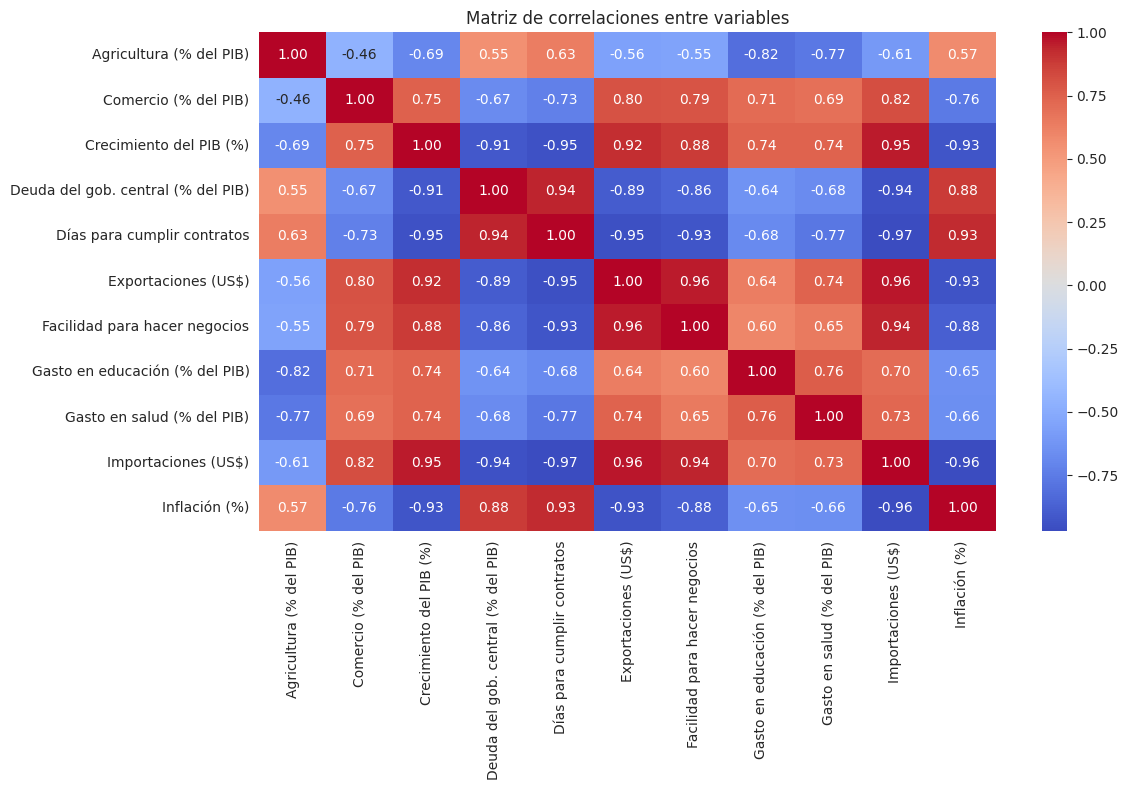

In [19]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_final_imputed.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de correlaciones entre variables')
plt.tight_layout()
plt.show()

4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

La matriz de correlaciones muestra que el crecimiento del PIB tiene una relación positiva fuerte con las importaciones (0,95) y las exportaciones (0,92). Por otro lado tiene una relación negativa fuerte con los días para cumplir contratos (-0,95) y la inflación (-0,93). Esto quiere decir que varios de los indicadores están relacionados entre sí y que sus cambios tienden a ir en direcciones similares o contrarias según el caso.

Por eso el análisis de componentes principales (PCA) resulta útil, ya que permite resumir la información de varias variables en menos componentes. De esta manera se puede construir un índice que facilite comparar el clima de inversión entre los países sin tener que analizar cada indicador por separado.

4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [20]:
### TU CÓDIGO AQUÍ ###
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_final_imputed)

### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [21]:
### TU CÓDIGO AQUÍ ###
from sklearn.decomposition import PCA
import numpy as np

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

varianza_acumulada = np.cumsum(
    pca.explained_variance_ratio_
)

print("Varianza acumulada por componente:")
print(varianza_acumulada)

Varianza acumulada por componente:
[0.80432386 0.89486154 0.93597174 0.95991133 0.97641891 0.9864744
 0.99249496 0.99665217 0.99895635 0.99961687 1.        ]


5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

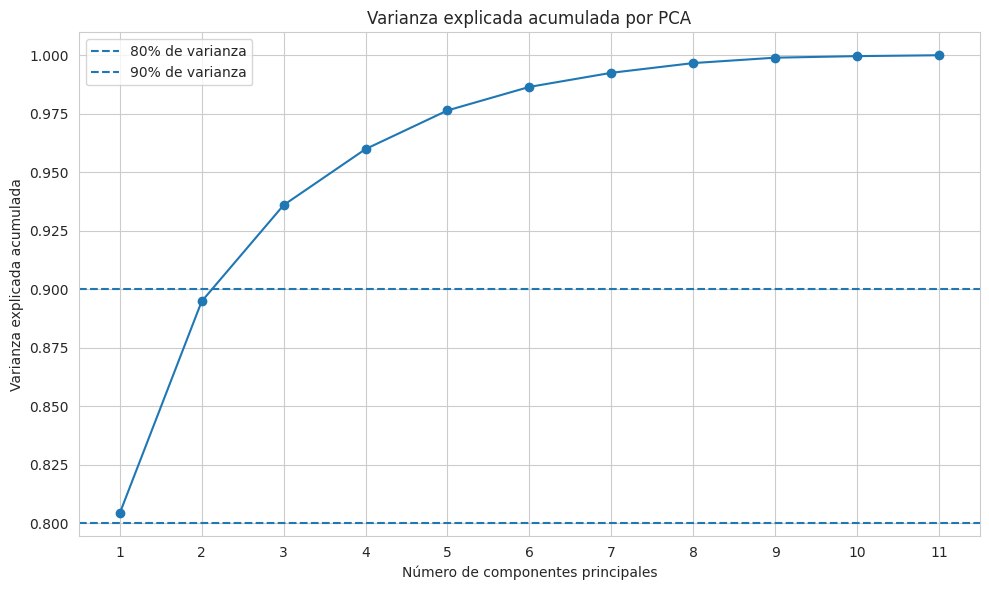

In [22]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker='o'
)

plt.axhline(y=0.80, linestyle='--', label='80% de varianza')
plt.axhline(y=0.90, linestyle='--', label='90% de varianza')

plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada por PCA')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

5.3. Realiza un análisis del gráfico anterior.

El primer componente principal explica el 80,43 % de la varianza total, mientras que los dos primeros explican el 89,49 % y los tres primeros llegan al 93,60 %. Esto quiere decir que el primer componente logra resumir gran parte de la información de los indicadores analizados, aunque al incluir más componentes se puede recoger una mayor parte de las diferencias que hay en los datos.

Por eso usar el primer componente para construir el índice es una buena opción ya que permite reunir la información en una sola medida y comparar más fácilmente los países. Sin embargo, el 19,57 % de la varianza queda sin explicar por este componente, así que el índice no recoge toda la información de los indicadores. Aun así, sirve como una medida resumida para comparar el clima de inversión, teniendo en cuenta esta limitación.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [23]:
### TU CÓDIGO AQUÍ ###
pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(X_scaled)

6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

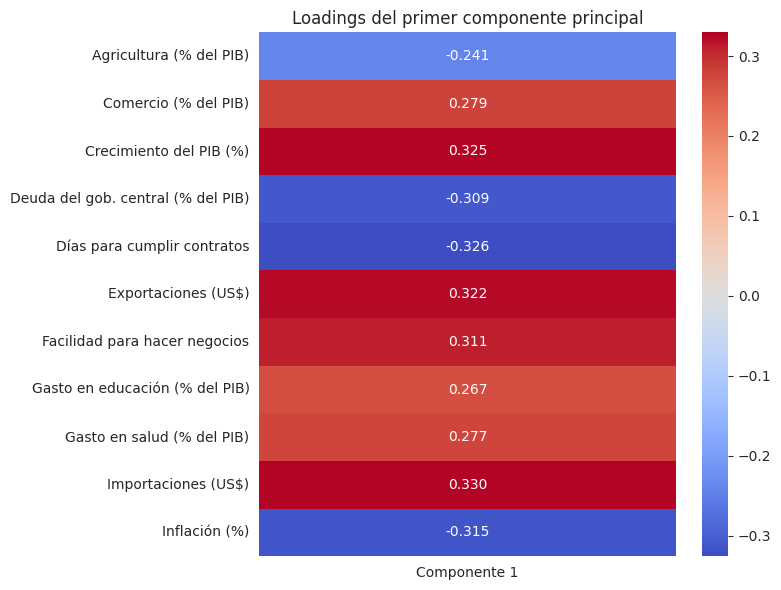

In [24]:
### TU CÓDIGO AQUÍ ###
loadings = pd.DataFrame(
    pca_final.components_.T,
    index=df_final_imputed.columns,
    columns=['Componente 1']
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.3f'
)

plt.title('Loadings del primer componente principal')
plt.tight_layout()
plt.show()

6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?

Los mayores pesos positivos del primer componente son las importaciones (0,330), el crecimiento del PIB (0,325) y las exportaciones (0,322). Por otro lado, los pesos negativos más altos corresponden a los días para cumplir contratos (-0,326), la inflación (-0,315) y la deuda del gobierno central como porcentaje del PIB (-0,309). Esto muestra que el componente está relacionado principalmente con la actividad económica y el comercio, mientras que las otras variables tienen una relación inversa con él.

Podemos utilizar el componente 1 como un índice aproximado para comparar el clima de inversión entre los países, porque reúne varios indicadores en una sola medida. Sin embargo hay que tener en cuenta que depende de las variables seleccionadas y no incluye todos los factores que pueden influir en la inversión. Además las cargas muestran relaciones estadísticas pero no demuestran que una variable cause cambios en otra. Por eso el componente sirve como una referencia para comparar países aunque no es suficiente por sí solo para evaluar completamente su clima de inversión.

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [27]:
df_final['Indice_Inversion'] = X_pca[:, 0]
df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,-5.93
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,-1.93
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [28]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.sort_values(
    by='Indice_Inversion',
    ascending=False
)

df_final.head()

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09


7.2. Convierte 'ShortName' en una columna del dataframe.

In [29]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.reset_index()

7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

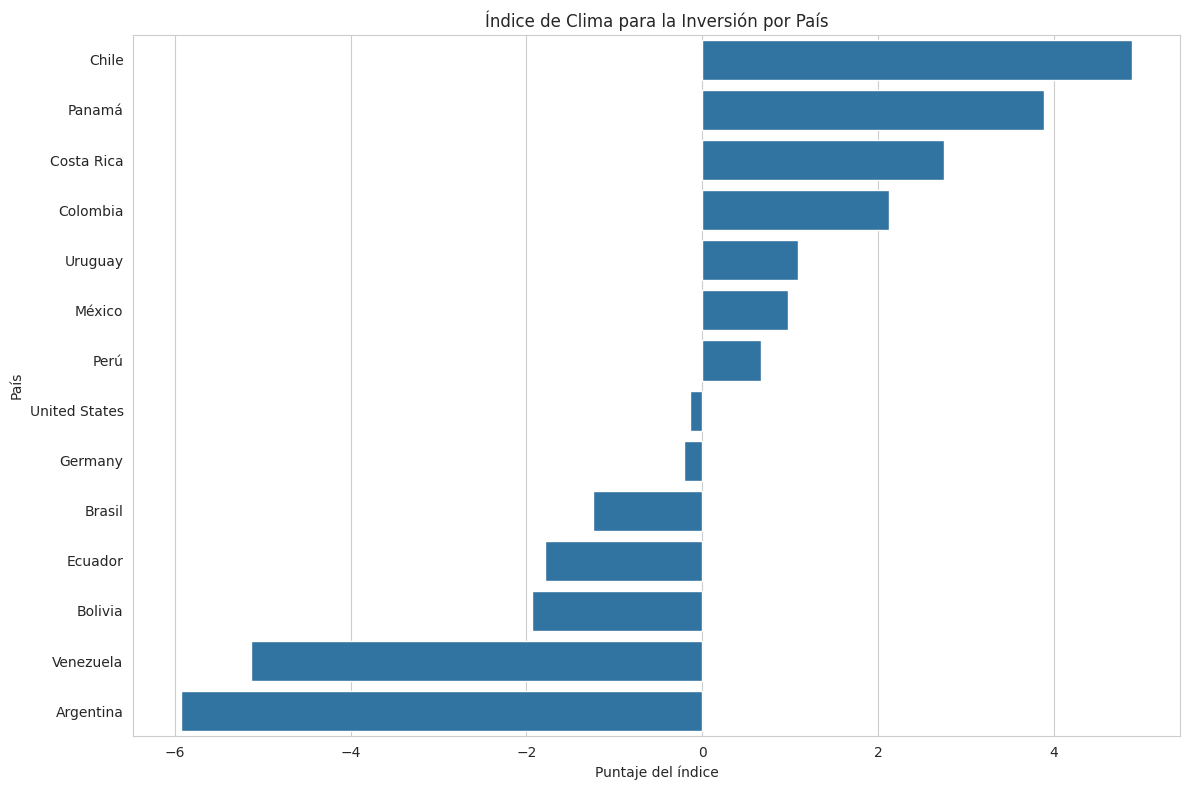

In [30]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(12, 8))

sns.barplot(
    data=df_final,
    x='Indice_Inversion',
    y='ShortName'
)

plt.title('Índice de Clima para la Inversión por País')
plt.xlabel('Puntaje del índice')
plt.ylabel('País')
plt.tight_layout()
plt.show()

7.4. Analiza los resultados del gráfico y redacta una conclusiones para el MinCIT sobre el clima de inversión en la región, quiénes son nuestros competidores en la atracción de capitales extranjeros y por qué, en qué son mejores que Colombia.

Los resultados del índice muestran que Chile ocupa el primer lugar, con 4,89 puntos, seguido de Panamá, con 3,89, y Costa Rica, con 2,75. Colombia se ubica en el cuarto lugar, con 2,13 puntos. Esto indica que de acuerdo con los indicadores analizados y el primer componente principal, estos tres países obtuvieron puntuaciones superiores a Colombia en el índice de clima de inversión.

Al comparar estos resultados con los pesos del primer componente, se observa que el crecimiento del PIB, las importaciones y las exportaciones tienen los mayores pesos positivos, mientras que los días para cumplir contratos, la inflación y la deuda del gobierno central presentan los mayores pesos negativos en valor absoluto

Se recomienda al Ministerio de Comercio, Industria y Turismo (MinCIT) utilizar el índice como punto de partida para comparar estos indicadores entre Colombia y los países mejor posicionados. Esto permitiría identificar las diferencias más relevantes y orientar las estrategias de mejora del clima de inversión y de atracción de inversión extranjera directa. El ranking sirve como herramienta de comparación, pero no mide directamente la inversión extranjera recibida por cada país.
